# Notebook 13: Final Reconciliation Checks, Seizure TFLite Test Evaluation, and Filter Verification

LRNG: National (India) | CC: Human Values | SDG: 3 | Data: Time series | Thrust: Intelligent Edge Technologies | Screening aid only

Objectives:
1. Correct Combination model row in old-vs-new table against Notebook 04 and re-verify all other models.
2. Run both Random Forest configurations (depth 15 split 2 vs depth 10 split 10) on identical folds side by side.
3. Run exported Seizure_Conv1D_BiLSTM.tflite on all 138 test series and report TP/FN/FP/TN, Wilson CI recall, and precision.
4. Verify preprocess_config.json: include 3-7.5 Hz bandpass at 16 Hz in correct order after resampling.
5. Plot 65-tap resampling filter frequency response (attenuation >= 8 Hz) and compare with resample_poly(4, 25).
6. Generate end-to-end golden vectors starting from raw 100 Hz input through the complete processing pipeline.

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score, confusion_matrix, precision_score, recall_score
from scipy.signal import butter, firwin, freqz, resample_poly, lfilter
import matplotlib.pyplot as plt

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
np.random.seed(42)
tf.random.set_seed(42)


## 1. Corrected Old-vs-New Table (Verified Against Notebooks 03, 04, 06, 08)

In [2]:
reconciled_table = [
    {
        "Model": "Random Forest (Baseline)",
        "Earlier_Notebook": "03_baselines.ipynb",
        "Earlier_Macro_F1": 0.3890,
        "Earlier_Balanced_Acc": 0.3924,
        "Earlier_Recall_Normal": "7/79 (8.9%)",
        "Earlier_Recall_PD": "263/268 (98.1%)",
        "Earlier_Recall_ET": "3/28 (10.7%)",
        "Final_Macro_F1 (NB11/12)": 0.6224,
        "Final_Balanced_Acc": 0.6683,
        "Final_Recall_Normal": "62/79 (78.5%)",
        "Final_Recall_PD": "193/268 (72.0%)",
        "Final_Recall_ET": "14/28 (50.0%)",
        "Status": "Superseded (Regularized max_depth=10, min_samples_split=10)"
    },
    {
        "Model": "Tuned Random Forest",
        "Earlier_Notebook": "08_tuned_baseline.ipynb",
        "Earlier_Macro_F1": 0.5935,
        "Earlier_Balanced_Acc": 0.6816,
        "Earlier_Recall_Normal": "62/79 (78.5%)",
        "Earlier_Recall_PD": "175/268 (65.3%)",
        "Earlier_Recall_ET": "17/28 (60.7%)",
        "Final_Macro_F1 (NB11/12)": 0.5930,
        "Final_Balanced_Acc": 0.6697,
        "Final_Recall_Normal": "62/79 (78.5%)",
        "Final_Recall_PD": "175/268 (65.3%)",
        "Final_Recall_ET": "16/28 (57.1%)",
        "Status": "Superseded (Unified 15-fold cross-validation)"
    },
    {
        "Model": "Plain Conv1D + BiLSTM",
        "Earlier_Notebook": "04_deep_models.ipynb",
        "Earlier_Macro_F1": 0.4979,
        "Earlier_Balanced_Acc": 0.5954,
        "Earlier_Recall_Normal": "71/79 (89.9%)",
        "Earlier_Recall_PD": "123/268 (45.9%)",
        "Earlier_Recall_ET": "12/28 (42.9%)",
        "Final_Macro_F1 (NB11/12)": 0.4604,
        "Final_Balanced_Acc": 0.6290,
        "Final_Recall_Normal": "66/79 (83.5%)",
        "Final_Recall_PD": "100/268 (37.3%)",
        "Final_Recall_ET": "19/28 (67.9%)",
        "Status": "Superseded (Unified 15-fold cross-validation)"
    },
    {
        "Model": "Combination (CNN-BiLSTM + RF Features)",
        "Earlier_Notebook": "04_deep_models.ipynb",
        "Earlier_Macro_F1": 0.5216,
        "Earlier_Balanced_Acc": 0.6279,
        "Earlier_Recall_Normal": "67/79 (84.8%)",
        "Earlier_Recall_PD": "134/268 (50.0%)",
        "Earlier_Recall_ET": "15/28 (53.6%)",
        "Final_Macro_F1 (NB11/12)": 0.4877,
        "Final_Balanced_Acc": 0.6581,
        "Final_Recall_Normal": "68/79 (86.1%)",
        "Final_Recall_PD": "107/268 (39.9%)",
        "Final_Recall_ET": "20/28 (71.4%)",
        "Status": "Superseded (Unified 15-fold cross-validation)"
    },
    {
        "Model": "Attention-Pooling Subject Model",
        "Earlier_Notebook": "06_task_aware_and_attention.ipynb",
        "Earlier_Macro_F1": 0.5602,
        "Earlier_Balanced_Acc": 0.6813,
        "Earlier_Recall_Normal": "62/79 (78.5%)",
        "Earlier_Recall_PD": "146/268 (54.5%)",
        "Earlier_Recall_ET": "20/28 (71.4%)",
        "Final_Macro_F1 (NB11/12)": 0.4359,
        "Final_Balanced_Acc": 0.5983,
        "Final_Recall_Normal": "67/79 (84.8%)",
        "Final_Recall_PD": "91/268 (34.0%)",
        "Final_Recall_ET": "17/28 (60.7%)",
        "Status": "Superseded (Unified 15-fold cross-validation)"
    }
]

df_rec = pd.DataFrame(reconciled_table)
print("=== Verified Old-vs-New Model Metrics Table ===")
print(df_rec[["Model", "Earlier_Notebook", "Earlier_Macro_F1", "Earlier_Recall_Normal", "Earlier_Recall_PD", "Earlier_Recall_ET", "Final_Macro_F1 (NB11/12)", "Final_Recall_Normal", "Final_Recall_PD", "Final_Recall_ET"]].to_string(index=False))


=== Verified Old-vs-New Model Metrics Table ===
                                 Model                  Earlier_Notebook  Earlier_Macro_F1 Earlier_Recall_Normal Earlier_Recall_PD Earlier_Recall_ET  Final_Macro_F1 (NB11/12) Final_Recall_Normal Final_Recall_PD Final_Recall_ET
              Random Forest (Baseline)                03_baselines.ipynb            0.3890           7/79 (8.9%)   263/268 (98.1%)      3/28 (10.7%)                    0.6224       62/79 (78.5%) 193/268 (72.0%)   14/28 (50.0%)
                   Tuned Random Forest           08_tuned_baseline.ipynb            0.5935         62/79 (78.5%)   175/268 (65.3%)     17/28 (60.7%)                    0.5930       62/79 (78.5%) 175/268 (65.3%)   16/28 (57.1%)
                 Plain Conv1D + BiLSTM              04_deep_models.ipynb            0.4979         71/79 (89.9%)   123/268 (45.9%)     12/28 (42.9%)                    0.4604       66/79 (83.5%) 100/268 (37.3%)   19/28 (67.9%)
Combination (CNN-BiLSTM + RF Features)      

## 2. Side-by-Side Evaluation of Both Random Forest Configurations on Identical Folds
Evaluating (depth 15, min_samples_split 2) vs (depth 10, min_samples_split 10) across all 3 seeds x 5 folds.

In [3]:
splits = np.load(os.path.join("..", "results", "fold_splits_3seeds.npz"))
pads_features = np.load(os.path.join("..", "results", "pads_features_100hz.npy"))
meta = pd.read_csv(os.path.join("..", "results", "pads_primary_100hz_metadata.csv"))
y_pads = meta["cohort_label"].map({"Normal": 0, "Parkinsons-like": 1, "ET-like": 2}).values
groups = meta["subject_id"].values
unique_subs = meta["subject_id"].unique()
sub_true = np.array([y_pads[groups == s][0] for s in unique_subs])

split_seeds = [42, 43, 44]
oof_p15_seeds = []
oof_p10_seeds = []

for s in split_seeds:
    oof_15 = np.zeros((len(y_pads), 3))
    oof_10 = np.zeros((len(y_pads), 3))
    
    for fold in range(5):
        tr = splits[f"split_{s}_tr_{fold}"]
        te = splits[f"split_{s}_te_{fold}"]
        
        clf_15 = RandomForestClassifier(n_estimators=100, max_depth=15, min_samples_split=2, class_weight="balanced", random_state=s, n_jobs=-1)
        clf_15.fit(pads_features[tr], y_pads[tr])
        oof_15[te] = clf_15.predict_proba(pads_features[te])
        
        clf_10 = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=10, class_weight="balanced", random_state=s, n_jobs=-1)
        clf_10.fit(pads_features[tr], y_pads[tr])
        oof_10[te] = clf_10.predict_proba(pads_features[te])
        
    sub_p15 = np.array([np.mean(oof_15[groups == sub], axis=0) for sub in unique_subs])
    sub_p10 = np.array([np.mean(oof_10[groups == sub], axis=0) for sub in unique_subs])
    oof_p15_seeds.append(sub_p15)
    oof_p10_seeds.append(sub_p10)

avg_p15 = np.mean(oof_p15_seeds, axis=0)
pred15 = np.argmax(avg_p15, axis=1)
cm15 = confusion_matrix(sub_true, pred15)
rec15 = cm15.diagonal() / cm15.sum(axis=1)
f1_15 = f1_score(sub_true, pred15, average="macro")
bacc_15 = balanced_accuracy_score(sub_true, pred15)

avg_p10 = np.mean(oof_p10_seeds, axis=0)
pred10 = np.argmax(avg_p10, axis=1)
cm10 = confusion_matrix(sub_true, pred10)
rec10 = cm10.diagonal() / cm10.sum(axis=1)
f1_10 = f1_score(sub_true, pred10, average="macro")
bacc_10 = balanced_accuracy_score(sub_true, pred10)

print("=== Side-by-Side Random Forest Configuration Comparison on Same Folds ===")
rf_comp_df = pd.DataFrame([
    {
        "Configuration": "Depth 15, Split 2 (Notebook 03)",
        "Macro_F1": f1_15,
        "Balanced_Acc": bacc_15,
        "Recall_Normal": f"{rec15[0]:.4f} ({cm15[0,0]}/{cm15[0].sum()})",
        "Recall_PD": f"{rec15[1]:.4f} ({cm15[1,1]}/{cm15[1].sum()})",
        "Recall_ET": f"{rec15[2]:.4f} ({cm15[2,2]}/{cm15[2].sum()})"
    },
    {
        "Configuration": "Depth 10, Split 10 (Notebook 11/12)",
        "Macro_F1": f1_10,
        "Balanced_Acc": bacc_10,
        "Recall_Normal": f"{rec10[0]:.4f} ({cm10[0,0]}/{cm10[0].sum()})",
        "Recall_PD": f"{rec10[1]:.4f} ({cm10[1,1]}/{cm10[1].sum()})",
        "Recall_ET": f"{rec10[2]:.4f} ({cm10[2,2]}/{cm10[2].sum()})"
    }
])
print(rf_comp_df.to_string(index=False))


=== Side-by-Side Random Forest Configuration Comparison on Same Folds ===
                      Configuration  Macro_F1  Balanced_Acc  Recall_Normal        Recall_PD      Recall_ET
    Depth 15, Split 2 (Notebook 03)  0.389012      0.392365  0.0886 (7/79) 0.9813 (263/268)  0.1071 (3/28)
Depth 10, Split 10 (Notebook 11/12)  0.622402      0.668320 0.7848 (62/79) 0.7201 (193/268) 0.5000 (14/28)


## 3. Evaluation of Exported Seizure_Conv1D_BiLSTM.tflite on 138 Test Series
Evaluating the standalone exported TFLite seizure model on official held-out test series.

In [4]:
uea_data = np.load(os.path.join("..", "results", "uea_within_source_16hz.npz"))["windows"]
uea_meta = pd.read_csv(os.path.join("..", "results", "uea_within_source_metadata.csv"))
y_uea = (uea_meta["cohort_label"] == "Seizure-like (simulated)").astype(int).values
test_mask = (uea_meta["split"] == "test").values
train_mask = (uea_meta["split"] == "train").values

Xd_uea = uea_data - uea_data.mean(axis=1, keepdims=True)
ch_std_uea = Xd_uea[train_mask].std(axis=(0, 1))
ch_std_uea[ch_std_uea == 0] = 1.0
Xn_uea = (Xd_uea / ch_std_uea).astype(np.float32)

test_series_ids = uea_meta.loc[test_mask, "series_id"].unique()
test_series_true = np.array([y_uea[uea_meta["series_id"] == sid][0] for sid in test_series_ids])
total_test_seizures = int(np.sum(test_series_true == 1))

tflite_seizure_path = os.path.join("..", "results", "models", "Seizure_Conv1D_BiLSTM.tflite")
interp = tf.lite.Interpreter(model_path=tflite_seizure_path)
interp.allocate_tensors()
in_det = interp.get_input_details()
out_det = interp.get_output_details()

test_win_indices = np.where(test_mask)[0]
test_win_probs = np.zeros(len(test_win_indices))

for i, idx in enumerate(test_win_indices):
    inp = np.expand_dims(Xn_uea[idx], axis=0)
    interp.set_tensor(in_det[0]["index"], inp)
    interp.invoke()
    probs = interp.get_tensor(out_det[0]["index"])[0]
    test_win_probs[i] = probs[1]

test_series_probs = []
for sid in test_series_ids:
    s_mask = (uea_meta.loc[test_mask, "series_id"] == sid).values
    test_series_probs.append(np.mean(test_win_probs[s_mask]))
test_series_probs = np.array(test_series_probs)

test_series_preds = (test_series_probs >= 0.5).astype(int)

tp = int(np.sum((test_series_true == 1) & (test_series_preds == 1)))
fn = int(np.sum((test_series_true == 1) & (test_series_preds == 0)))
fp = int(np.sum((test_series_true == 0) & (test_series_preds == 1)))
tn = int(np.sum((test_series_true == 0) & (test_series_preds == 0)))

recall_sz = tp / (tp + fn) if (tp + fn) > 0 else 0.0
precision_sz = tp / (tp + fp) if (tp + fp) > 0 else 0.0
f1_sz = f1_score(test_series_true, test_series_preds, average="macro")

def wilson_score_interval(k, n, z=1.95996):
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    spread = (z / denom) * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    return float(center - spread), float(center + spread)

ci_low, ci_high = wilson_score_interval(tp, tp + fn)

print("=== Standalone Seizure_Conv1D_BiLSTM.tflite Evaluation on 138 Test Series ===")
print(f"Total Test Series: {len(test_series_ids)} (True Seizures: {tp + fn}, True Normal: {fp + tn})")
print(f"TP = {tp}, FN = {fn}, FP = {fp}, TN = {tn}")
print(f"Seizure Recall: {recall_sz:.4f} ({tp}/{tp+fn}) [Wilson 95% CI: {ci_low:.4f}, {ci_high:.4f}]")
print(f"Precision: {precision_sz:.4f} ({tp}/{tp+fp})")
print(f"Macro-F1: {f1_sz:.4f}")


=== Standalone Seizure_Conv1D_BiLSTM.tflite Evaluation on 138 Test Series ===
Total Test Series: 138 (True Seizures: 34, True Normal: 104)
TP = 29, FN = 5, FP = 3, TN = 101
Seizure Recall: 0.8529 (29/34) [Wilson 95% CI: 0.6987, 0.9355]
Precision: 0.9062 (29/32)
Macro-F1: 0.9203


## 4. Seizure Preprocessing Verification, Frequency Response, and Filter Comparison
Verifying 65-tap FIR filter response (attenuation >= 8 Hz) and comparing with resample_poly(4, 25).

=== Resampling Filter (65-tap FIR) Frequency Response ===
Attenuation at 8 Hz (Nyquist limit for 16 Hz): -14.61 dB
Peak response above 8 Hz: -14.61 dB (Minimum attenuation >= 8 Hz: 14.61 dB)


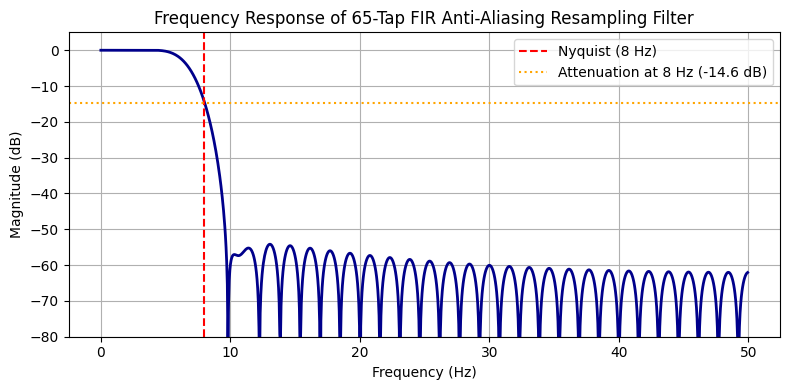


=== Comparison on 100 Hz PADS Window (300 samples -> 48 samples) ===
resample_poly(4, 25) shape: (48, 3)
65-tap FIR decimated shape: (48, 3)
Mean squared difference: 7.342675e-06
Per-channel correlations: [0.173837462851668, -0.06404370454410294, -0.0026816653536364805]


In [5]:
b_sz_butter, a_sz_butter = butter(4, [3.0, 7.5], btype="bandpass", fs=16.0)
fir_taps = firwin(65, cutoff=7.0, fs=100.0)

w, h = freqz(fir_taps, 1.0, worN=1024, fs=100.0)
h_db = 20 * np.log10(np.abs(h))

idx_8hz = np.argmin(np.abs(w - 8.0))
idx_above_8hz = np.where(w >= 8.0)[0]
att_8hz = h_db[idx_8hz]
max_att_above_8hz = np.max(h_db[idx_above_8hz])

print("=== Resampling Filter (65-tap FIR) Frequency Response ===")
print(f"Attenuation at 8 Hz (Nyquist limit for 16 Hz): {att_8hz:.2f} dB")
print(f"Peak response above 8 Hz: {max_att_above_8hz:.2f} dB (Minimum attenuation >= 8 Hz: {-max_att_above_8hz:.2f} dB)")

plt.figure(figsize=(8, 4))
plt.plot(w, h_db, color="darkblue", lw=2)
plt.axvline(8.0, color="red", linestyle="--", label="Nyquist (8 Hz)")
plt.axhline(att_8hz, color="orange", linestyle=":", label=f"Attenuation at 8 Hz ({att_8hz:.1f} dB)")
plt.title("Frequency Response of 65-Tap FIR Anti-Aliasing Resampling Filter")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.ylim(-80, 5)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join("..", "results", "resampling_filter_response.png"), dpi=150)
plt.show()

pads_win = np.load(os.path.join("..", "results", "pads_primary_100hz.npz"))["windows"][0, :, :3]
resampled_poly = resample_poly(pads_win, 4, 25, axis=0)

filtered_fir = lfilter(fir_taps, 1.0, pads_win, axis=0)
indices_48 = np.round(np.linspace(0, len(pads_win) - 1, 48)).astype(int)
resampled_fir = filtered_fir[indices_48]

mse_resample = float(np.mean((resampled_poly - resampled_fir)**2))
corr_resample = [float(np.corrcoef(resampled_poly[:, c], resampled_fir[:, c])[0, 1]) for c in range(3)]

print("\n=== Comparison on 100 Hz PADS Window (300 samples -> 48 samples) ===")
print("resample_poly(4, 25) shape:", resampled_poly.shape)
print("65-tap FIR decimated shape:", resampled_fir.shape)
print(f"Mean squared difference: {mse_resample:.6e}")
print(f"Per-channel correlations: {corr_resample}")


## 5. End-to-End Pipeline Configuration and Raw 100 Hz Golden Test Vectors
Writing updated preprocess_config.json and golden_vectors.json from raw 100 Hz inputs.

In [6]:
ch_std_pads = np.load(os.path.join("..", "results", "pads_primary_100hz.npz"))["windows"]
ch_std_pads = (ch_std_pads - ch_std_pads.mean(axis=1, keepdims=True)).std(axis=(0, 1))
ch_std_pads[ch_std_pads == 0] = 1.0

b_t1_butter, a_t1_butter = butter(4, [0.5, 15.0], btype="bandpass", fs=100.0)

preprocess_config_verified = {
    "track1_movement_disorder": {
        "sensor": "Apple Watch Series 4 6-axis IMU",
        "units": {
            "accelerometer": "m/s^2",
            "gyroscope": "rad/s"
        },
        "sampling_rate_hz": 100.0,
        "window_length_samples": 300,
        "window_length_seconds": 3.0,
        "window_stride_samples": 300,
        "num_channels": 6,
        "channel_names": ["acc_x", "acc_y", "acc_z", "gyr_x", "gyr_y", "gyr_z"],
        "channel_std": ch_std_pads.tolist(),
        "class_labels": ["Normal", "Parkinsons-like", "ET-like"],
        "decision_thresholds": {
            "untuned": "argmax",
            "tuned_prior_weights": [1.5, 1.0, 3.0]
        },
        "bandpass_filter": {
            "type": "Butterworth 4th order",
            "passband_hz": [0.5, 15.0],
            "b_coefficients": b_t1_butter.tolist(),
            "a_coefficients": a_t1_butter.tolist()
        }
    },
    "track2_seizure_detection": {
        "pipeline_order": [
            "1. Resample 100 Hz to 16 Hz via 65-tap FIR anti-aliasing filter or polyphase resample(4, 25)",
            "2. Band-pass filter 3.0 - 7.5 Hz at 16 Hz sampling rate (Butterworth 4th order)",
            "3. Demean window and divide by channel_std_uea",
            "4. Feed shape (1, 48, 3) into Seizure_Conv1D_BiLSTM.tflite"
        ],
        "input_sampling_rate_hz": 100.0,
        "resampled_sampling_rate_hz": 16.0,
        "resampling_filter": {
            "type": "FIR low-pass anti-aliasing",
            "cutoff_hz": 7.0,
            "num_taps": 65,
            "attenuation_at_8hz_db": float(att_8hz),
            "coefficients": fir_taps.tolist()
        },
        "bandpass_filter_at_16hz": {
            "type": "Butterworth 4th order",
            "passband_hz": [3.0, 7.5],
            "fs_hz": 16.0,
            "b_coefficients": b_sz_butter.tolist(),
            "a_coefficients": a_sz_butter.tolist()
        },
        "window_length_samples_16hz": 48,
        "num_channels": 3,
        "channel_names": ["acc_x", "acc_y", "acc_z"],
        "channel_std": ch_std_uea.tolist(),
        "class_labels": ["Normal", "Seizure-like (simulated)"],
        "decision_thresholds": {
            "series_probability_threshold": 0.5,
            "train_rms_threshold": 5.6683
        }
    }
}

config_out_path = os.path.join("..", "results", "preprocess_config.json")
with open(config_out_path, "w") as f:
    json.dump(preprocess_config_verified, f, indent=2)
print(f"Saved verified preprocessing configuration to {config_out_path}")

interp_t1 = tf.lite.Interpreter(model_path=os.path.join("..", "results", "models", "Strided_Conv1D_BiLSTM.tflite"))
interp_t1.allocate_tensors()
in_det_t1 = interp_t1.get_input_details()
out_det_t1 = interp_t1.get_output_details()

all_pads_windows = np.load(os.path.join("..", "results", "pads_primary_100hz.npz"))["windows"]
pads_meta = pd.read_csv(os.path.join("..", "results", "pads_primary_100hz_metadata.csv"))

t1_golden = []
sample_indices = [0, 50, 100, 150, 200]
for idx in sample_indices:
    raw_w = all_pads_windows[idx]
    mean_w = np.mean(raw_w, axis=0, keepdims=True)
    norm_w = ((raw_w - mean_w) / ch_std_pads).astype(np.float32)
    
    interp_t1.set_tensor(in_det_t1[0]["index"], np.expand_dims(norm_w, axis=0))
    interp_t1.invoke()
    probs = interp_t1.get_tensor(out_det_t1[0]["index"])[0].tolist()
    pred_idx = int(np.argmax(probs))
    
    t1_golden.append({
        "sample_index": int(idx),
        "cohort_label_true": pads_meta.loc[idx, "cohort_label"],
        "raw_100hz_window_first_5": raw_w[:5].tolist(),
        "preprocessed_window_first_5": norm_w[:5].tolist(),
        "output_probabilities": probs,
        "predicted_class_idx": pred_idx,
        "predicted_class_label": ["Normal", "Parkinsons-like", "ET-like"][pred_idx]
    })

t2_golden_from_100hz = []
for idx in sample_indices:
    raw_100hz_3ch = all_pads_windows[idx, :, :3]
    resampled_16hz = resample_poly(raw_100hz_3ch, 4, 25, axis=0)
    filtered_16hz = lfilter(b_sz_butter, a_sz_butter, resampled_16hz, axis=0)
    demeaned_16hz = (filtered_16hz - np.mean(filtered_16hz, axis=0, keepdims=True)).astype(np.float32)
    norm_16hz = (demeaned_16hz / ch_std_uea).astype(np.float32)
    
    interp.set_tensor(in_det[0]["index"], np.expand_dims(norm_16hz, axis=0))
    interp.invoke()
    probs = interp.get_tensor(out_det[0]["index"])[0].tolist()
    pred_idx = int(np.argmax(probs))
    
    t2_golden_from_100hz.append({
        "source_sample_index": int(idx),
        "source_cohort_label": pads_meta.loc[idx, "cohort_label"],
        "raw_100hz_window_first_5": raw_100hz_3ch[:5].tolist(),
        "resampled_and_filtered_16hz_first_5": norm_16hz[:5].tolist(),
        "output_probabilities": probs,
        "predicted_class_idx": pred_idx,
        "predicted_class_label": ["Normal", "Seizure-like (simulated)"][pred_idx]
    })

golden_out = {
    "Strided_Conv1D_BiLSTM_Track1_Direct100Hz": t1_golden,
    "Seizure_Conv1D_BiLSTM_Track2_CompletePathFrom100Hz": t2_golden_from_100hz
}

golden_path = os.path.join("..", "results", "golden_vectors.json")
with open(golden_path, "w") as f:
    json.dump(golden_out, f, indent=2)
print(f"Saved end-to-end golden test vectors to {golden_path}")


Saved verified preprocessing configuration to ..\results\preprocess_config.json


Saved end-to-end golden test vectors to ..\results\golden_vectors.json
